In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

EMB = Path("../data/embeddings/emb")

X = np.load(EMB / "embeddings.npy")
ids = pd.read_csv(EMB / "speech_ids.csv")
q = pd.read_parquet(
    "../data/processed/speeches.parquet",
    columns=[
        "speechID", 
        "date", 
        "party", 
        "nameOfHouse", 
        "nameOfMeeting", 
        "text"
    ]
)

df = ids.merge(q, on="speechID", how="left", validate="one_to_one")
print(X.shape, len(df), "党が空の行:", df["party"].isna().sum())
print(df["party"].value_counts().to_dict())

(88297, 768) 88297 党が空の行: 0
{'立憲': 24267, '国民': 12288, '維新': 9760, '自民': 9588, '共産': 7457, '公明': 6841, '中道': 5296, '参政': 4088, 'れいわ': 3637, 'その他': 2647, 'みらい': 1451, '保守': 589, '社民': 388}


In [2]:
d = df["date"]
df["gov"] = (
    (df["party"] == "自民")
    | ((df["party"] == "公明") & (d < "2025-10-10"))
    | ((df["party"] == "維新") & (d >= "2025-10-20"))
)
print(df.groupby("party")["gov"].mean().round(2).sort_values())

party
その他    0.00
みらい    0.00
れいわ    0.00
中道     0.00
保守     0.00
共産     0.00
参政     0.00
国民     0.00
立憲     0.00
社民     0.00
維新     0.39
公明     0.53
自民     1.00
Name: gov, dtype: float64


説明できるばらつきの割合: [0.18  0.094]


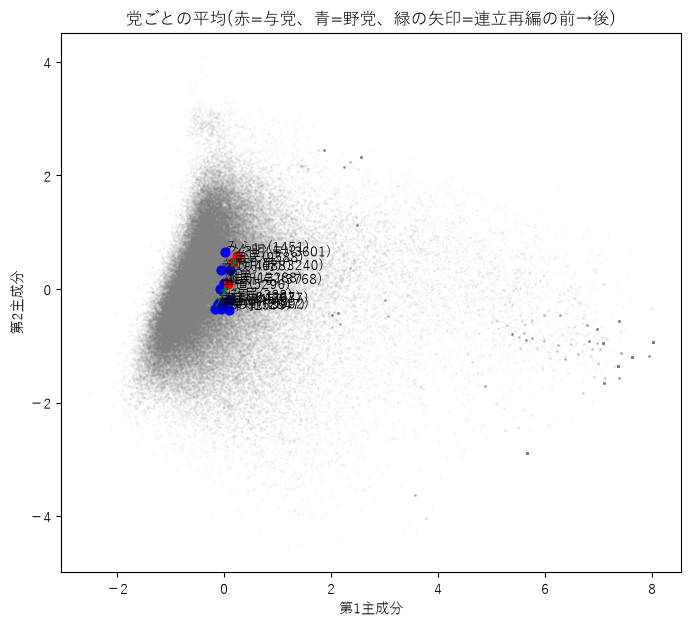

In [3]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

plt.rcParams["font.family"] = "Yu Gothic"

pca = PCA(n_components=2)
Z = pca.fit_transform(X)
df["pc1"], df["pc2"] = Z[:, 0], Z[:, 1]
print("説明できるばらつきの割合:", pca.explained_variance_ratio_.round(3))

# 公明と維新は、与党の時期と野党の時期を分けて点にする
df["label"] = df["party"]
for p in ["公明", "維新"]:
    m = df["party"] == p
    df.loc[m, "label"] = p + df.loc[m, "gov"].map({True: "(与)", False: "(野)"})

g = df.groupby("label").agg(pc1=("pc1", "mean"), pc2=("pc2", "mean"),
                            n=("pc1", "size"), gov=("gov", "mean")) 

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(df["pc1"], df["pc2"], s=1, alpha=0.05, color="gray")
for lab, r, in g.iterrows():
    color = "red" if r["gov"] > 0.5 else "blue"
    ax.scatter(r["pc1"], r["pc2"], color=color, s=40)
    ax.annotate(f"{lab}({int(r['n'])})", (r["pc1"], r["pc2"]), fontsize=10)

# 公明・維新の「前→後」を矢印で結ぶ
for p, before, after in [("公明", "(与)", "(野)"), ("維新", "(野)", "(与)")]:
    a, b = g.loc[p + before], g.loc[p + after]
    ax.annotate(
        "", 
        xy=(b["pc1"], b["pc2"]), 
        xytext=(a["pc1"], a["pc2"]), 
        arrowprops=dict(arrowstyle="->", color="green")
    ) 

ax.set_xlabel("第1主成分"); ax.set_ylabel("第2主成分")
ax.set_title("党ごとの平均(赤=与党、青=野党、緑の矢印=連立再編の前→後)")
Path("../outputs").mkdir(exist_ok=True)
plt.savefig("../outputs/pca_parties.png", dpi=150, bbox_inches="tight")
plt.show() 



In [4]:
out = df[df["pc1"] > 3]
print(len(out), "件")
print(out["party"].value_counts().to_dict())
print(
    "文字数の中央値:", 
    out["text"].str.len().median(), 
    "(全体:", 
    df["text"].str.len().median(), 
    ")"
)
for _, r in out.sample(len(out), random_state=0).iterrows():
    print(f"\n[{r['party']}・{r['nameOfMeeting']}] {r['text'][:150]}")

3521 件
{'立憲': 742, '国民': 528, '自民': 493, '維新': 479, '公明': 398, '共産': 189, '中道': 188, '参政': 145, 'れいわ': 129, 'その他': 128, 'みらい': 57, '保守': 30, '社民': 15}
文字数の中央値: 28.0 (全体: 371.0 )

[公明・地方創生及びデジタル社会の形成等に関する特別委員会] 以上で終わります。ありがとうございました。

[自民・文教科学委員会] 副大臣、いかがでしょうか。聞かせてください。

[保守・法務委員会] それでは終わります。どうも。

[立憲・外交防衛委員会] 大変有り難いお言葉、ありがとうございます。 トップレベルで連絡を取り合ってくださるという理解でよろしいですね。

[自民・政治改革に関する特別委員会] ありがとうございます。 我が党も、一致点を見出すべく、真摯に協議をしてまいります。その思いで臨んでまいります。 以上です。ありがとうございました。

[自民・予算委員会第二分科会] ありがとうございます。 以上で質問を終わります。ありがとうございました。

[公明・厚生労働委員会] ありがとうございました。 いろいろな観点からの御意見をいただきましたので、参考にしたいと思います。 ありがとうございます。終わります。

[公明・財務金融委員会] 終わります。ありがとうございました。

[維新・内閣委員会] 残りはまた今度やりたいと思います。 ありがとうございました。

[その他・内閣委員会] 終わります。

[公明・農林水産委員会] はい。 終わります。ありがとうございました。

[れいわ・内閣委員会] 時間がなくなりました。 御丁寧な御回答、どうもありがとうございました。

[立憲・厚生労働委員会] 受け取ってくださるということでよろしいですね。

[立憲・外交防衛委員会] 終わります。ありがとうございました。

[れいわ・総務委員会] 時間になったので終わります。 元上司の湯本局長には質問できなくて申し訳ありませんでした。 以上で終わります。ありがとうございます。

[国民・予算委員会] 終わります。ありがとうございました。

[立憲・こども・子育て・若者活躍に関する特別委員会] 御異議ないと認めます。 そ

In [5]:
df["n_char"] = df["text"].str.len()

print(
    "第一主成分と文字数の相関:", 
    round(np.corrcoef(df["pc1"], np.log1p(df["n_char"]))[0, 1], 3)
)
print("右側(pc1>3)の件数:", (df["pc1"] > 3).sum())
print("右側の文字数:", df.loc[df["pc1"] > 3, "n_char"].describe(percentiles=[.5, .9, .99]).round(0).to_dict())

print("\n区切りの長さごとに、除かれる発言")
for th in [30, 50, 80, 100, 150]:
    short = df["n_char"] < th
    print(f"  {th:>3}文字未満: {short.sum():>6}件({short.mean():.1%})"
          f"  うち右側の発言 {(short & (df['pc1'] > 3)).sum()}件")

print("\n100文字未満の発言の、党ごとの割合")
print((df["n_char"] < 100).groupby(df["party"]).mean().round(3).sort_values().to_dict())

第一主成分と文字数の相関: -0.743
右側(pc1>3)の件数: 3521
右側の文字数: {'count': 3521.0, 'mean': 35.0, 'std': 23.0, 'min': 3.0, '50%': 28.0, '90%': 69.0, '99%': 102.0, 'max': 156.0}

区切りの長さごとに、除かれる発言
   30文字未満:   2565件(2.9%)  うち右側の発言 1879件
   50文字未満:   5014件(5.7%)  うち右側の発言 2697件
   80文字未満:   8665件(9.8%)  うち右側の発言 3338件
  100文字未満:  11120件(12.6%)  うち右側の発言 3482件
  150文字未満:  17125件(19.4%)  うち右側の発言 3520件

100文字未満の発言の、党ごとの割合
{'みらい': 0.057, '参政': 0.077, '公明': 0.099, '国民': 0.104, '自民': 0.105, '維新': 0.11, '中道': 0.12, 'その他': 0.135, '立憲': 0.153, '共産': 0.162, 'れいわ': 0.165, '保守': 0.182, '社民': 0.209}


残った発言: 77177 件
説明できるばらつきの割合: [0.137 0.074]

第一成分との相関係数
  与党かどうか: 0.179
  文字数(対数): -0.091
  日付        : 0.129

第二主成分との相関係数
  与党かどうか: 0.162
  文字数(対数): -0.192
  日付        : 0.012


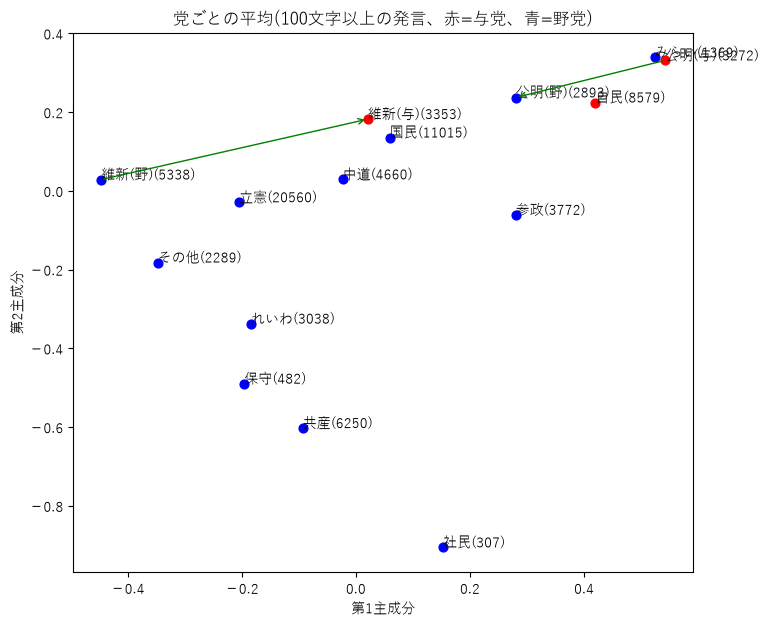

In [6]:
df["n_char"] = df["text"].str.len()
keep = (df["n_char"] >= 100).to_numpy()
d2 = df[keep].reset_index(drop=True)
X2 = X[keep]
print("残った発言:", len(d2), "件")

pca2 = PCA(n_components=2)
Z2 = pca2.fit_transform(X2)
d2["pc1"], d2["pc2"] = Z2[:, 0], Z2[:, 1]
print("説明できるばらつきの割合:", pca2.explained_variance_ratio_.round(3))

print("\n第一成分との相関係数")
print("  与党かどうか:", round(np.corrcoef(d2["pc1"], d2["gov"])[0, 1], 3))
print("  文字数(対数):", round(np.corrcoef(d2["pc1"], np.log1p(d2["n_char"]))[0, 1], 3))
print("  日付        :", round(np.corrcoef(d2["pc1"], d2["date"].astype("int64"))[0, 1], 3))
print("\n第二主成分との相関係数")
print("  与党かどうか:", round(np.corrcoef(d2["pc2"], d2["gov"])[0, 1], 3))
print("  文字数(対数):", round(np.corrcoef(d2["pc2"], np.log1p(d2["n_char"]))[0, 1], 3))
print("  日付        :", round(np.corrcoef(d2["pc2"], d2["date"].astype("int64"))[0, 1], 3))

g2 = d2.groupby("label").agg(
    pc1=("pc1", "mean"), pc2=("pc2", "mean"),
    n=("pc1", "size"), gov=("gov", "mean")
)
fig, ax = plt.subplots(figsize=(8, 7))
for lab, r in g2.iterrows():
    color = "red" if r["gov"] > 0.5 else "blue"
    ax.scatter(r["pc1"], r["pc2"], color=color, s=40)
    ax.annotate(f"{lab}({int(r['n'])})", (r["pc1"], r["pc2"]), fontsize=10)
for p, before, after in [("公明", "(与)", "(野)"), ("維新", "(野)", "(与)")]:
    a, b = g2.loc[p + before], g2.loc[p + after]
    ax.annotate("", xy=(b["pc1"], b["pc2"]), xytext=(a["pc1"], a["pc2"]), 
                arrowprops=dict(arrowstyle="->", color="green"))
ax.set_xlabel("第1主成分"); ax.set_ylabel("第2主成分")
ax.set_title("党ごとの平均(100文字以上の発言、赤=与党、青=野党)")
Path("../outputs").mkdir(exist_ok=True)
plt.savefig("../outputs/pca_parties_min100.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# (1) 党の違いで、主成分のばらつきの何割を説明できるか
for c in ["pc1", "pc2"]:
    party_mean = d2.groupby("label")[c].transform("mean")
    total = ((d2[c] - d2[c].mean()) ** 2).sum()
    between = ((party_mean - d2[c].mean()) ** 2).sum()
    print(c, "党で説明できる割合:", round(between / total, 3))

# (2) 2025-10-10 の前と後で、党ごとの第1主成分の平均がどれだけ動いたか
d2["after"] = d2["date"] >= "2025-10-10"
t = d2.groupby(["party", "after"])["pc1"].mean().unstack()
t.columns = ["前", "後"]
t["変化"] = t["後"] - t["前"]
t["件数(後)"] = d2[d2["after"]].groupby("party").size()
print(t.round(3).sort_values("変化"))

pc1 党で説明できる割合: 0.077
pc2 党で説明できる割合: 0.111
           前      後     変化  件数(後)
party                            
参政     0.577  0.267 -0.310   3615
公明     0.542  0.280 -0.262   2893
共産    -0.085 -0.106 -0.021   2546
立憲    -0.239 -0.133  0.106   6675
国民    -0.046  0.129  0.175   6622
れいわ   -0.252 -0.046  0.206   1002
その他   -0.446 -0.177  0.269    839
保守    -0.427 -0.085  0.343    326
自民     0.219  0.638  0.419   4117
維新    -0.446  0.021  0.467   3353
みらい      NaN  0.524    NaN   1369
中道       NaN -0.023    NaN   4660
社民       NaN  0.153    NaN    307


In [8]:
for house in ["衆議院", "参議院"]:
    s = d2[d2["nameOfHouse"] == house]
    m = s.groupby(["party", "after"])["pc1"].mean().unstack()
    n = s.groupby(["party", "after"]).size().unstack()
    t = pd.DataFrame({
        "前": m[False], "後": m[True], "変化": m[True] - m[False], 
        "件数(前)": n[False], "件数(後)": n[True], 
    })
    print(house)
    print(t.round(3).sort_values("変化"))
    print()


衆議院
           前      後     変化   件数(前)   件数(後)
party                                     
参政     0.682  0.394 -0.288   143.0  1644.0
公明     0.646  0.448 -0.198  1401.0   381.0
立憲    -0.234 -0.294 -0.060  8957.0  1851.0
国民     0.127  0.107 -0.020  2463.0  3530.0
その他   -0.710 -0.633  0.077   548.0   331.0
共産     0.139  0.219  0.080  1709.0   948.0
れいわ   -0.293 -0.202  0.092  1331.0   260.0
自民     0.337  0.774  0.438  2602.0  2226.0
維新    -0.323  0.166  0.488  3081.0  1503.0
みらい      NaN  0.547    NaN     NaN  1182.0
中道       NaN -0.028    NaN     NaN  4641.0
保守    -0.427    NaN    NaN   156.0     NaN

参議院
           前      後     変化   件数(前)   件数(後)
party                                     
公明     0.464  0.255 -0.209  1871.0  2506.0
共産    -0.276 -0.298 -0.023  1995.0  1598.0
立憲    -0.244 -0.072  0.172  4904.0  4809.0
れいわ   -0.174  0.008  0.182   705.0   742.0
その他   -0.286  0.120  0.406   902.0   508.0
国民    -0.263  0.156  0.419  1918.0  3079.0
自民     0.054  0.477  0.423  1860.0  1891.0
維新

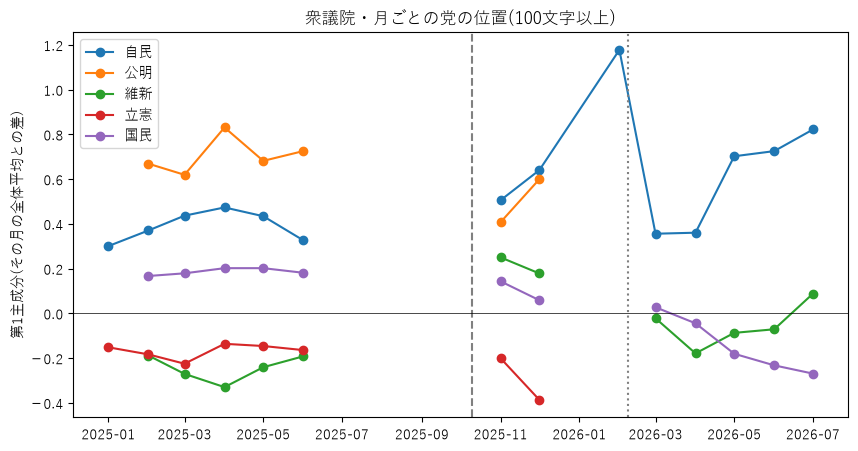

In [9]:
d2h = d2[d2["nameOfHouse"] == "衆議院"].copy()   # 衆議院だけ。d2 はそのまま残る
d2h["month"] = d2h["date"].dt.to_period("M")

monthly_all = d2h.groupby("month")["pc1"].mean()               # その月の全体平均
pm = d2h.groupby(["month", "party"])["pc1"].mean().unstack()   # 月×党の平均
cnt = d2h.groupby(["month", "party"]).size().unstack()         # 月×党の件数
rel = pm.sub(monthly_all, axis=0).where(cnt >= 30)             # 全体平均との差。30件未満は空にする

fig, ax = plt.subplots(figsize=(10, 5))
for p in ["自民", "公明", "維新", "立憲", "国民"]:
    ax.plot(rel.index.to_timestamp(), rel[p], marker="o", label=p)
ax.axvline(pd.Timestamp("2025-10-10"), color="gray", linestyle="--")   # 公明の離脱
ax.axvline(pd.Timestamp("2026-02-08"), color="gray", linestyle=":")    # 衆院選
ax.axhline(0, color="black", linewidth=0.5)
ax.set_ylabel("第1主成分(その月の全体平均との差)")
ax.set_title("衆議院・月ごとの党の位置(100文字以上)")
ax.legend()
plt.savefig("../outputs/pc1_monthly_relative_shu.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
parties = ["自民", "公明", "維新", "立憲", "国民", "中道"]
print(cnt[parties].fillna(0).astype(int))   # 月ごとの件数(信頼できる月かどうか)

gap = pm[parties].sub(pm["自民"], axis=0).where(cnt[parties] >= 30)   # 自民との差
print(gap.drop(columns="自民").round(2))

party     自民   公明    維新    立憲   国民    中道
month                                   
2025-01   45    5    15   123   13     0
2025-02  873  337   559  1954  397     0
2025-03  496  237   504  1385  413     0
2025-04  553  411  1001  2778  791     0
2025-05  408  272   643  1839  545     0
2025-06  214  132   349   828  293     0
2025-08    8    4     6    29    7     0
2025-09    5    3     4    21    4     0
2025-10    0    0     0     0    0     0
2025-11  251  241   167  1251  328     0
2025-12  168  140   119   600  175     0
2026-02   37    0     1     0    2   110
2026-03  264    0   203     0  631   914
2026-04  467    0   348     0  904  1373
2026-05  358    0   278     0  785  1202
2026-06  554    0   279     0  531   802
2026-07  127    0   108     0  174   240
party      公明    維新    立憲    国民    中道
month                                
2025-01   NaN   NaN -0.45   NaN   NaN
2025-02  0.30 -0.56 -0.55 -0.20   NaN
2025-03  0.18 -0.71 -0.66 -0.26   NaN
2025-04  0.36 -0.80 -0.61 -0.27

In [11]:
pd.set_option("display.max_colwidth", 300)

def show_ends(data, party, k=5):
    s = data[data["party"] == party].sort_values("pc1")
    cols = ["date", "nameOfMeeting", "pc1", "text"]
    print(f"===== {party}:pc1 が低い {k} 件 =====")
    for _, r in s.head(k)[cols].iterrows():
        print(r["date"].date(), r["nameOfMeeting"], round(r["pc1"], 2))
        print(r["text"][:250], "\n")
    print(f"===== {party}:pc1 が高い {k} 件 =====")
    for _, r in s.tail(k)[cols].iterrows():
        print(r["date"].date(), r["nameOfMeeting"], round(r["pc1"], 2))
        print(r["text"][:250], "\n")

show_ends(d2h, "自民")
show_ends(d2h, "立憲")


===== 自民:pc1 が低い 5 件 =====
2025-02-27 予算委員会第五分科会 -1.99
やはり施設の中に、介護を分かっている人が専門家にならないと、ほかの分野もみんなそうなんだけれども、ベンダーに丸投げしちゃうから、大体使えないものを作って、使わなくなっちゃうという悪循環ですからね。是非そこを検討してもらいたいというふうに思います。 次に、延命治療についてであります。 これはちょっと私の地元の例を申し上げますけれども、支援者の方がおられて、そのお母さん、百六歳、デイサービスに行っていて、救急車で運ばれた、そうしたら脳溢血だったということでありました。意識がなかったということでありま 

2025-02-14 予算委員会 -1.97
先生、御質問ありがとうございます。なかなか難しい御質問なので、どう答えたらいいかなとは思うんですけれども。 まず、人口減少を急激に止めることはできないんだと思うんですよね。今、政府も、いろいろな政策は、ある程度人口減少というものを前提にいろいろと立案していると思うんですけれども、基礎自治体がどのくらいの規模がいいのかというのはなかなか難しい。そこはまさに市町村長にお聞きになっていただいた方がいいかというふうには思うんですが。 平成の大合併自体は私は必要だったというふうに思っているんですね。やはり 

2025-02-14 予算委員会 -1.96
委員、御質問ありがとうございます。 まず、ちょっとこれも早口で言いますが、デジタルクリエーティブ産業とは何かという御説明をする暇がなかったんですけれども、主に、日進月歩のデジタル技術を使ったコンテンツ制作、それからデザイン、それから映像、それからゲーム、アプリ開発、こういうものに特化した産業のことを言います。 どういうプレーヤーがいるかというと、例えばITのスタートアップもそうだと思いますし、例えば映画会社のような、基本的にエンタメ産業とも直接つながっているので、こういうところもそうかもしれませ 

2025-02-27 予算委員会第五分科会 -1.92
喫煙でもあれだけやったんですからね、農水省がやっているところ。だから、省庁を乗り越えてやれるというのは絶対できると思いますので、これはやはり早急な対応が必要だと思います。かなりの数の方が多分苦しんでいるというところでありまし

In [12]:
PROC = r"緊急動議|付帯決議案|案文の朗読|趣旨の説明に代え"
m = d2["text"].str.contains(PROC)
print("手続きの発言:", m.sum(), "件")
print(d2[m].groupby("party").size().sort_values(ascending=False))

手続きの発言: 104 件
party
立憲    40
中道    35
自民    23
国民     5
維新     1
dtype: int64


In [13]:
CASUAL = r"でしょう|じゃない|ちゃう|ちゃっ|よね|だって|んです|んだ|けど|みたいな|ちょっと"
d2["casual"] = d2["text"].str.count(CASUAL) / d2["n_char"] * 1000   # 1000文字あたりの回数

print("第1主成分との相関:", round(np.corrcoef(d2["pc1"], d2["casual"])[0, 1], 3))

# 衆議院の維新・国民・自民で、再編の前後に話し方が変わったか
h = d2[d2["nameOfHouse"] == "衆議院"]
print(h[h["party"].isin(["維新", "国民", "自民"])]
      .groupby(["party", "after"])["casual"].mean().unstack().round(2))

第1主成分との相関: -0.619
after  False  True 
party              
国民      4.54   5.18
維新      7.34   4.73
自民      3.20   2.09


In [14]:
from sklearn.linear_model import LinearRegression

Z = np.column_stack([d2["casual"], np.log1p(d2["n_char"])])   # 説明に使う2つ:くだけ度、長さ
lr = LinearRegression().fit(Z, d2["pc1"])
d2["pc1_adj"] = d2["pc1"] - lr.predict(Z)                      # 話し方と長さで説明できる分を引いた残り
print("話し方と長さで説明できる割合:", round(lr.score(Z, d2["pc1"]), 3))

h = d2[d2["nameOfHouse"] == "衆議院"]
t = (h[h["party"].isin(["維新", "国民", "自民"])]
     .groupby(["party", "after"])[["pc1", "pc1_adj"]].mean().unstack().round(2))
print(t)

話し方と長さで説明できる割合: 0.42
        pc1       pc1_adj      
after False True    False True 
party                          
国民     0.13  0.11   -0.04  0.02
維新    -0.32  0.17   -0.23  0.04
自民     0.34  0.77    0.08  0.41


In [15]:
import pandas as pd

q3 = pd.read_parquet("../data/processed/speeches.parquet",
                     columns=["speechID", "date", "nameOfMeeting", "speaker",
                              "speakerGroup", "party", "text", "speechURL"])

# (a) 怪しかった 2025-02-14 予算委員会の「御質問ありがとうございます」
s = q3[(q3["date"] == "2025-02-14") & (q3["nameOfMeeting"] == "予算委員会")
       & q3["text"].str.contains("質問ありがとうございます", na=False)]
print(s[["speaker", "speakerGroup", "party", "speechURL"]].to_string())

# (b) 議員以外がよく使う言い回しを含む発言が、全体で何件あるか
GUEST = r"御質問ありがとうございます|質問ありがとうございます|公述人として|参考人として"
g = q3[q3["text"].str.contains(GUEST, na=False)]
print("\n言い回しを含む発言:", len(g), "件")
print(g.groupby("party").size().sort_values(ascending=False))
print(g.groupby("speaker").size().sort_values(ascending=False).head(15))

     speaker speakerGroup party                                               speechURL
4353    山本一太   自由民主党・国民の声    自民  https://kokkai.ndl.go.jp/txt/121705261X01020250214/220
4360    山本一太   自由民主党・国民の声    自民  https://kokkai.ndl.go.jp/txt/121705261X01020250214/234
4365    山本一太   自由民主党・国民の声    自民  https://kokkai.ndl.go.jp/txt/121705261X01020250214/242
4369    山本一太   自由民主党・国民の声    自民  https://kokkai.ndl.go.jp/txt/121705261X01020250214/249
4373    山本一太   自由民主党・国民の声    自民  https://kokkai.ndl.go.jp/txt/121705261X01020250214/257
4376    山本一太   自由民主党・国民の声    自民  https://kokkai.ndl.go.jp/txt/121705261X01020250214/262
4387    山本一太   自由民主党・国民の声    自民  https://kokkai.ndl.go.jp/txt/121705261X01020250214/282
4395    山本一太   自由民主党・国民の声    自民  https://kokkai.ndl.go.jp/txt/121705261X01020250214/292

言い回しを含む発言: 261 件
party
立憲     84
国民     56
自民     37
維新     20
共産     19
公明     15
れいわ    13
中道      6
その他     5
参政      5
保守      1
dtype: int64
speaker
臼木秀剛     14
杉尾秀哉     11
山本一太      8
山井和則      7
浜口誠  

In [19]:
q2 = q3[["date", "speaker", "speakerGroup", "party"]]
print(q2.groupby("party")["date"].agg(["min", "max", "size"]))

f = q2[q2["speaker"].str.contains("福島", na=False)]
print(f.groupby(["speaker", "speakerGroup", "party"])["date"].agg(["min", "max", "size"]))

             min        max   size
party                             
その他   2025-02-03 2026-07-23   2647
みらい   2026-02-25 2026-07-27   1451
れいわ   2025-01-23 2026-07-24   3637
中道    2026-02-18 2026-07-27   5296
保守    2025-02-25 2026-07-16    589
公明    2025-01-23 2026-07-24   6841
共産    2025-01-22 2026-07-27   7457
参政    2025-02-25 2026-07-27   4088
国民    2025-01-23 2026-07-27  12288
社民    2026-02-18 2026-07-16    388
立憲    2025-01-23 2026-07-24  24267
維新    2025-01-23 2026-07-27   9760
自民    2025-01-23 2026-07-27   9588
                                  min        max  size
speaker speakerGroup party                            
福島みずほ   社会民主党        社民    2026-03-31 2026-07-16   224
        立憲民主・社民・無所属  立憲    2025-03-13 2026-01-23   186
福島伸享    有志の会         その他   2025-02-07 2025-12-15   228


In [20]:
# (1) 会派ごとに、割り当てた党と、発言者の人数・件数
grp = q2.groupby(["speakerGroup", "party"]).agg(人数=("speaker", "nunique"), 件数=("speaker", "size"))
print(grp.sort_values("件数", ascending=False).to_string())

# (2) 合同会派の発言者の一覧
for gname in ["立憲民主・社民・無所属"]:
    print("\n=====", gname)
    print(q2[q2["speakerGroup"] == gname].groupby("speaker").size().sort_values(ascending=False).to_string())

# (3) みらいの安野貴博議員の発言が、どの会派に入っているか
print(q2[q2["speaker"].str.contains("安野", na=False)]
      .groupby(["speakerGroup", "party"])["date"].agg(["min", "max", "size"]))

                     人数     件数
speakerGroup party            
立憲民主党・無所属    立憲     140  12737
日本維新の会       維新      70   9760
日本共産党        共産      21   7457
自由民主党・無所属の会  自民     319   7249
公明党          公明      52   6841
立憲民主・社民・無所属  立憲      51   6802
国民民主党・無所属クラブ 国民      36   6633
国民民主党・新緑風会   国民      25   5655
中道改革連合・無所属   中道      46   5296
立憲民主・無所属     立憲      38   4728
参政党          参政      32   4088
れいわ新選組       れいわ     16   3637
自由民主党        自民      92   2325
チームみらい       みらい     11   1247
各派に属しない議員    その他     11    948
有志の会         その他      4    745
日本保守党        保守       5    589
沖縄の風         その他      3    531
社会民主党        社民       2    388
無所属          その他      6    248
チームみらい・無所属の会 みらい      2    204
ＮＨＫから国民を守る党  その他      2    117
改革の会         その他      2     20
減税保守こども      その他      2     20
ＮＨＫ党         その他      1     18
自由民主党・国民の声   自民       1     14

===== 立憲民主・社民・無所属
speaker
村田享子      354
石橋通宏      274
大椿ゆうこ     266
古賀之士      265
塩村あやか     256
川田龍平      246
柴愼一       244
杉尾秀哉   